# Experimento de Análise de Anúncios do Trocabook

Este experimento tem como objetivo analisar os anúncios cadastrados no Trocabook, buscando identificar padrões relacionados à quantidade de anúncios, modalidades de negociação, categorias dos livros, autores e evolução das publicações ao longo do tempo.

A análise utilizará informações presentes nos anúncios da plataforma, como tipo de negociação, categorias, autores e data de criação. A partir desses dados, serão realizadas análises descritivas e diagnósticas que permitam compreender como os anúncios estão distribuídos e como seu comportamento evolui ao longo do tempo.

Entre os aspectos analisados estarão a distribuição dos anúncios por modalidade de negociação, as categorias e autores mais presentes, a relação entre categorias e tipos de negociação e a quantidade de novos anúncios registrados em diferentes períodos.

A dimensão temporal será baseada no campo `dataCriacao`, responsável por registrar o momento em que cada anúncio foi criado. Esse campo permitirá construir indicadores relacionados à evolução da quantidade de anúncios e às variações observadas entre os períodos analisados.

O experimento utilizará inicialmente dados simulados para validar as etapas de preparação, transformação, análise e geração de indicadores antes da integração com os dados reais armazenados no Firebase Cloud Firestore.

Os resultados obtidos poderão posteriormente ser utilizados pelo serviço de Analytics para fornecer indicadores e insights ao dashboard administrativo do Trocabook. As análises produzidas neste experimento terão caráter descritivo e diagnóstico, não sendo utilizadas para prever quais livros, categorias, autores ou modalidades de negociação serão anunciados futuramente.

## 1. Bibliotecas utilizadas

Para a realização das análises serão utilizadas bibliotecas Python voltadas à manipulação, transformação e visualização dos dados.

- **Pandas:** utilizado para organizar os anúncios em estruturas tabulares, realizar agrupamentos, contagens, transformações e preparar os dados para as diferentes análises.
- **NumPy:** utilizado como suporte para operações numéricas que possam ser necessárias durante o experimento.
- **Matplotlib:** utilizado para construir visualizações gráficas que auxiliem na interpretação da distribuição e da evolução dos anúncios.

Outras bibliotecas poderão ser adicionadas posteriormente caso surja uma necessidade específica durante o desenvolvimento das análises.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Dados utilizados no experimento

Para validar a metodologia de análise antes da integração com o Firebase Cloud Firestore, será utilizado inicialmente um conjunto de dados simulados representando anúncios cadastrados no Trocabook.

Os dados simulados buscarão representar os principais campos necessários para as análises deste experimento, incluindo o identificador do anúncio, o usuário anunciante, o livro anunciado, o tipo de negociação, o título, os autores, as categorias e a data de criação.

Embora o modelo real de anúncio possua outros campos utilizados pelo funcionamento da plataforma, serão considerados neste experimento apenas aqueles relevantes para as análises propostas.

Os anúncios serão distribuídos ao longo de diferentes períodos e possuirão diferentes modalidades de negociação, categorias e autores, permitindo analisar a distribuição das publicações e sua evolução ao longo do tempo.

### 2.1 Simulação dos anúncios

Como o experimento ainda não está integrado ao Firebase Cloud Firestore, será criado um conjunto de dados simulados para representar anúncios publicados no Trocabook.

A simulação utilizará diferentes livros, autores, categorias e modalidades de negociação. Os anúncios também serão distribuídos ao longo do tempo por meio do campo `dataCriacao`, permitindo posteriormente construir análises temporais da quantidade de novas publicações.

Os dados simulados não têm como objetivo reproduzir exatamente o comportamento futuro da plataforma, mas fornecer uma base controlada para validar as etapas de preparação, transformação, agrupamento e análise dos anúncios.

In [2]:
titulos_simulados = [
    "Dom Casmurro",
    "O Hobbit",
    "1984",
    "Orgulho e Preconceito",
    "O Pequeno Príncipe",
    "Harry Potter e a Pedra Filosofal",
    "Clean Code",
    "O Senhor dos Anéis",
    "A Revolução dos Bichos",
    "Percy Jackson e o Ladrão de Raios"
]

autores_simulados = [
    ["Machado de Assis"],
    ["J. R. R. Tolkien"],
    ["George Orwell"],
    ["Jane Austen"],
    ["Antoine de Saint-Exupéry"],
    ["J. K. Rowling"],
    ["Robert C. Martin"],
    ["J. R. R. Tolkien"],
    ["George Orwell"],
    ["Rick Riordan"]
]

categorias_simuladas = [
    ["Literatura Brasileira", "Clássicos"],
    ["Fantasia", "Aventura"],
    ["Ficção", "Clássicos"],
    ["Romance", "Clássicos"],
    ["Ficção", "Infantojuvenil"],
    ["Fantasia", "Infantojuvenil"],
    ["Tecnologia", "Programação"],
    ["Fantasia", "Aventura"],
    ["Ficção", "Clássicos"],
    ["Fantasia", "Aventura"]
]

Para representar a evolução das publicações ao longo do tempo, serão simulados 36 meses de histórico de anúncios.

A quantidade de novos anúncios poderá variar entre os meses, apresentando uma tendência geral de crescimento acompanhada de oscilações. Essa distribuição será independente daquela utilizada no experimento de previsão de usuários, evitando estabelecer artificialmente uma relação direta entre o crescimento de usuários e a quantidade de anúncios publicados.

Embora essa dimensão temporal seja utilizada neste experimento para analisar a evolução histórica dos anúncios, ela também poderá servir posteriormente como base para validar separadamente a metodologia de previsão da quantidade de novos anúncios.

In [3]:
anuncios_por_mes_simulados = [
    25, 28, 26, 31, 29, 33,
    30, 35, 32, 38, 36, 40,
    37, 42, 39, 45, 43, 47,
    44, 50, 46, 52, 49, 55,
    51, 57, 54, 60, 56, 63,
    59, 65, 62, 68, 64, 70
]

In [4]:
meses_simulados = pd.period_range(
    start="2024-01",
    periods=36,
    freq="M"
)

meses_simulados

PeriodIndex(['2024-01', '2024-02', '2024-03', '2024-04', '2024-05', '2024-06',
             '2024-07', '2024-08', '2024-09', '2024-10', '2024-11', '2024-12',
             '2025-01', '2025-02', '2025-03', '2025-04', '2025-05', '2025-06',
             '2025-07', '2025-08', '2025-09', '2025-10', '2025-11', '2025-12',
             '2026-01', '2026-02', '2026-03', '2026-04', '2026-05', '2026-06',
             '2026-07', '2026-08', '2026-09', '2026-10', '2026-11', '2026-12'],
            dtype='period[M]')

Para gerar os registros individuais dos anúncios, serão utilizadas distribuições controladas para a seleção dos livros e das modalidades de negociação.

A geração será realizada de forma reprodutível, permitindo que os mesmos dados simulados sejam obtidos sempre que o notebook for executado. Alguns livros poderão aparecer com maior frequência que outros, representando diferenças naturais na quantidade de anúncios publicados.

As modalidades `TROCA`, `VENDA` e `AMBOS` também serão distribuídas entre os anúncios, permitindo posteriormente comparar sua participação no conjunto de dados.

In [5]:
rng = np.random.default_rng(42)

In [6]:
probabilidades_livros = [
    0.08,
    0.14,
    0.11,
    0.07,
    0.10,
    0.13,
    0.06,
    0.12,
    0.09,
    0.10
]

sum(probabilidades_livros)

1.0

In [7]:
tipos_negociacao = [
    "TROCA",
    "VENDA",
    "AMBOS"
]

probabilidades_tipos = [
    0.40,
    0.35,
    0.25
]

sum(probabilidades_tipos)

1.0

In [8]:
anuncios_simulados = []

contador_anuncio = 1

for mes, quantidade in zip(
    meses_simulados,
    anuncios_por_mes_simulados
):
    for _ in range(quantidade):

        indice_livro = rng.choice(
            len(titulos_simulados),
            p=probabilidades_livros
        )

        tipo_negociacao = rng.choice(
            tipos_negociacao,
            p=probabilidades_tipos
        )

        anuncios_simulados.append({
            "id": f"A{contador_anuncio}",
            "uidUsuario": f"U{rng.integers(1, 201)}",
            "uidLivro": f"L{indice_livro + 1}",
            "titulo": titulos_simulados[indice_livro],
            "autores": autores_simulados[indice_livro],
            "categorias": categorias_simuladas[indice_livro],
            "tipoNegociacao": tipo_negociacao,
            "dataCriacao": mes.to_timestamp()
        })

        contador_anuncio += 1

In [9]:
anuncios = pd.DataFrame(anuncios_simulados)

anuncios.head()

,id,uidUsuario,uidLivro,titulo,autores,categorias,tipoNegociacao,dataCriacao
0,A1,U87,L8,O Senhor dos Anéis,[J. R. R. Tolkien],"[Fantasia, Aventura]",VENDA,2024-01-01
1,A2,U172,L8,O Senhor dos Anéis,[J. R. R. Tolkien],"[Fantasia, Aventura]",TROCA,2024-01-01
2,A3,U144,L10,Percy Jackson e o Ladrão de Raios,[Rick Riordan],"[Fantasia, Aventura]",AMBOS,2024-01-01
3,A4,U158,L2,O Hobbit,[J. R. R. Tolkien],"[Fantasia, Aventura]",VENDA,2024-01-01
4,A5,U157,L4,Orgulho e Preconceito,[Jane Austen],"[Romance, Clássicos]",AMBOS,2024-01-01


In [10]:
anuncios.tail()

,id,uidUsuario,uidLivro,titulo,autores,categorias,tipoNegociacao,dataCriacao
1656,A1657,U160,L4,Orgulho e Preconceito,[Jane Austen],"[Romance, Clássicos]",VENDA,2026-12-01
1657,A1658,U7,L4,Orgulho e Preconceito,[Jane Austen],"[Romance, Clássicos]",VENDA,2026-12-01
1658,A1659,U20,L3,1984,[George Orwell],"[Ficção, Clássicos]",TROCA,2026-12-01
1659,A1660,U139,L5,O Pequeno Príncipe,[Antoine de Saint-Exupéry],"[Ficção, Infantojuvenil]",VENDA,2026-12-01
1660,A1661,U66,L3,1984,[George Orwell],"[Ficção, Clássicos]",VENDA,2026-12-01


### 2.2 Visualização inicial

Após a geração dos dados simulados, será realizada uma inspeção inicial do conjunto de anúncios para verificar sua estrutura, quantidade de registros, tipos de dados e possíveis valores ausentes.

Essa etapa permite identificar eventuais inconsistências antes do início das transformações e análises.

In [11]:
anuncios.shape

(1661, 8)

In [12]:
anuncios.info()

<class 'pandas.DataFrame'>
RangeIndex: 1661 entries, 0 to 1660
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   id              1661 non-null   str           
 1   uidUsuario      1661 non-null   str           
 2   uidLivro        1661 non-null   str           
 3   titulo          1661 non-null   str           
 4   autores         1661 non-null   object        
 5   categorias      1661 non-null   object        
 6   tipoNegociacao  1661 non-null   str           
 7   dataCriacao     1661 non-null   datetime64[us]
dtypes: datetime64[us](1), object(2), str(5)
memory usage: 103.9+ KB


In [13]:
anuncios.isnull().sum()

id                0
uidUsuario        0
uidLivro          0
titulo            0
autores           0
categorias        0
tipoNegociacao    0
dataCriacao       0
dtype: int64

In [14]:
print(f"Quantidade de anúncios: {len(anuncios)}")
print(f"Quantidade de usuários anunciantes: {anuncios['uidUsuario'].nunique()}")
print(f"Quantidade de livros diferentes: {anuncios['uidLivro'].nunique()}")
print(f"Período inicial: {anuncios['dataCriacao'].min()}")
print(f"Período final: {anuncios['dataCriacao'].max()}")

Quantidade de anúncios: 1661
Quantidade de usuários anunciantes: 200
Quantidade de livros diferentes: 10
Período inicial: 2024-01-01 00:00:00
Período final: 2026-12-01 00:00:00


## 3. Preparação dos dados

Antes da realização das análises, os dados dos anúncios serão preparados para facilitar os agrupamentos e comparações realizados nas etapas seguintes.

Nesta etapa serão verificadas possíveis inconsistências nos campos utilizados pelo experimento, preparadas as informações que possuem múltiplos valores, como categorias e autores, e criada uma representação mensal a partir da data de criação dos anúncios.

Essas transformações permitirão utilizar o mesmo conjunto de dados em diferentes perspectivas de análise sem alterar os registros originais.

### 3.1 Validação dos campos

Inicialmente, serão verificados os valores presentes nos principais campos utilizados pelas análises. Essa validação permite identificar valores ausentes ou modalidades de negociação diferentes das esperadas antes da realização dos agrupamentos.

In [15]:
anuncios["tipoNegociacao"].value_counts()

tipoNegociacao
TROCA    659
VENDA    586
AMBOS    416
Name: count, dtype: int64

In [16]:
quantidade_sem_autor = anuncios["autores"].apply(len).eq(0).sum()
quantidade_sem_categoria = anuncios["categorias"].apply(len).eq(0).sum()

print(f"Anúncios sem autores: {quantidade_sem_autor}")
print(f"Anúncios sem categorias: {quantidade_sem_categoria}")

Anúncios sem autores: 0
Anúncios sem categorias: 0


### 3.2 Preparação das categorias e autores

Os campos `categorias` e `autores` podem armazenar múltiplos valores em um mesmo anúncio. Para permitir análises individuais de cada categoria e autor, serão criadas representações auxiliares dos dados utilizando a operação `explode()`.

Essa transformação cria uma linha para cada elemento presente na lista, mantendo as demais informações do anúncio. Os DataFrames auxiliares serão utilizados apenas nas análises que necessitem dessa separação, preservando o DataFrame original dos anúncios.

In [17]:
anuncios_por_categoria = anuncios.explode("categorias").copy()

anuncios_por_categoria[
    ["id", "titulo", "categorias", "tipoNegociacao"]
].head(10)

,id,titulo,categorias,tipoNegociacao
0,A1,O Senhor dos Anéis,Fantasia,VENDA
0,A1,O Senhor dos Anéis,Aventura,VENDA
1,A2,O Senhor dos Anéis,Fantasia,TROCA
1,A2,O Senhor dos Anéis,Aventura,TROCA
2,A3,Percy Jackson e o Ladrão de Raios,Fantasia,AMBOS
2,A3,Percy Jackson e o Ladrão de Raios,Aventura,AMBOS
3,A4,O Hobbit,Fantasia,VENDA
3,A4,O Hobbit,Aventura,VENDA
4,A5,Orgulho e Preconceito,Romance,AMBOS
4,A5,Orgulho e Preconceito,Clássicos,AMBOS


In [18]:
anuncios_por_categoria["categorias"].value_counts()

categorias
Fantasia                 832
Aventura                 630
Clássicos                569
Ficção                   492
Infantojuvenil           361
Literatura Brasileira    127
Romance                  109
Tecnologia               101
Programação              101
Name: count, dtype: int64

In [19]:
anuncios_por_autor = anuncios.explode("autores").copy()

anuncios_por_autor[
    ["id", "titulo", "autores", "tipoNegociacao"]
].head(10)

,id,titulo,autores,tipoNegociacao
0,A1,O Senhor dos Anéis,J. R. R. Tolkien,VENDA
1,A2,O Senhor dos Anéis,J. R. R. Tolkien,TROCA
2,A3,Percy Jackson e o Ladrão de Raios,Rick Riordan,AMBOS
3,A4,O Hobbit,J. R. R. Tolkien,VENDA
4,A5,Orgulho e Preconceito,Jane Austen,AMBOS
5,A6,A Revolução dos Bichos,George Orwell,VENDA
6,A7,1984,George Orwell,VENDA
7,A8,A Revolução dos Bichos,George Orwell,VENDA
8,A9,O Senhor dos Anéis,J. R. R. Tolkien,TROCA
9,A10,A Revolução dos Bichos,George Orwell,AMBOS


In [20]:
anuncios_por_autor["autores"].value_counts()

autores
J. R. R. Tolkien            455
George Orwell               333
J. K. Rowling               202
Rick Riordan                175
Antoine de Saint-Exupéry    159
Machado de Assis            127
Jane Austen                 109
Robert C. Martin            101
Name: count, dtype: int64

In [21]:
print(f"Anúncios originais: {len(anuncios)}")
print(f"Registros por categoria: {len(anuncios_por_categoria)}")
print(f"Registros por autor: {len(anuncios_por_autor)}")

Anúncios originais: 1661
Registros por categoria: 3322
Registros por autor: 1661


### 3.3 Preparação temporal

Para permitir a análise da evolução dos anúncios ao longo do tempo, será criada uma representação mensal a partir do campo `dataCriacao`.

O campo original será preservado, enquanto uma nova coluna denominada `mesCriacao` armazenará apenas o período correspondente ao ano e ao mês de criação de cada anúncio.

Essa transformação permitirá realizar agrupamentos mensais sem perder a data original dos registros.

In [22]:
anuncios["mesCriacao"] = (
    anuncios["dataCriacao"]
    .dt.to_period("M")
)

anuncios[
    ["id", "dataCriacao", "mesCriacao"]
].head()

,id,dataCriacao,mesCriacao
0,A1,2024-01-01,2024-01
1,A2,2024-01-01,2024-01
2,A3,2024-01-01,2024-01
3,A4,2024-01-01,2024-01
4,A5,2024-01-01,2024-01


In [23]:
print(f"Primeiro mês: {anuncios['mesCriacao'].min()}")
print(f"Último mês: {anuncios['mesCriacao'].max()}")
print(f"Quantidade de meses: {anuncios['mesCriacao'].nunique()}")

Primeiro mês: 2024-01
Último mês: 2026-12
Quantidade de meses: 36


## 4. Análise geral dos anúncios

Nesta etapa será analisado o comportamento geral dos anúncios presentes no conjunto de dados, considerando inicialmente a quantidade total de publicações e sua distribuição entre as modalidades de negociação disponíveis no Trocabook.

Essa análise fornece uma visão inicial sobre a oferta de livros na plataforma e permite identificar quais modalidades são mais utilizadas pelos anunciantes.

### 4.1 Quantidade total de anúncios

Inicialmente, será calculada a quantidade total de anúncios presentes no conjunto de dados simulado. Esse indicador representa o volume de publicações analisadas durante todo o período considerado pelo experimento.

In [24]:
quantidade_total_anuncios = anuncios["id"].nunique()

print(f"Quantidade total de anúncios: {quantidade_total_anuncios}")

Quantidade total de anúncios: 1661


### 4.2 Distribuição por tipo de negociação

Os anúncios do Trocabook podem ser disponibilizados para `TROCA`, `VENDA` ou `AMBOS`. A distribuição entre essas modalidades será analisada para identificar como os anúncios estão divididos entre as diferentes formas de negociação.

Serão consideradas tanto as quantidades absolutas quanto a participação percentual de cada modalidade no total de anúncios.

In [25]:
distribuicao_tipo = (
    anuncios["tipoNegociacao"]
    .value_counts()
    .rename_axis("tipoNegociacao")
    .reset_index(name="quantidadeAnuncios")
)

distribuicao_tipo

,tipoNegociacao,quantidadeAnuncios
0,TROCA,659
1,VENDA,586
2,AMBOS,416


In [26]:
distribuicao_tipo["percentual"] = (
    distribuicao_tipo["quantidadeAnuncios"]
    / quantidade_total_anuncios
    * 100
)

distribuicao_tipo

,tipoNegociacao,quantidadeAnuncios,percentual
0,TROCA,659,39.674895
1,VENDA,586,35.279952
2,AMBOS,416,25.045154


In [27]:
distribuicao_tipo["percentual"] = (
    distribuicao_tipo["percentual"]
    .round(2)
)

distribuicao_tipo

,tipoNegociacao,quantidadeAnuncios,percentual
0,TROCA,659,39.67
1,VENDA,586,35.28
2,AMBOS,416,25.05


Para facilitar a comparação entre as modalidades de negociação, a distribuição também será apresentada graficamente.

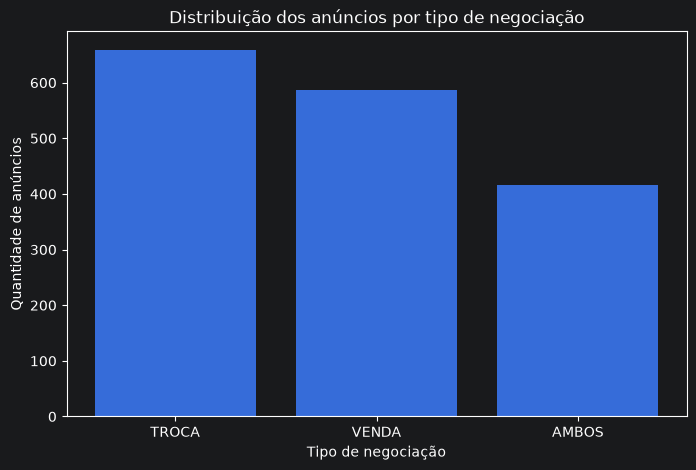

In [28]:
plt.figure(figsize=(8, 5))

plt.bar(
    distribuicao_tipo["tipoNegociacao"],
    distribuicao_tipo["quantidadeAnuncios"]
)

plt.title("Distribuição dos anúncios por tipo de negociação")
plt.xlabel("Tipo de negociação")
plt.ylabel("Quantidade de anúncios")

plt.show()

## 5. Análise por categoria

Nesta etapa serão analisadas as categorias associadas aos livros anunciados no Trocabook. Como um mesmo anúncio pode possuir mais de uma categoria, será utilizado o conjunto de dados preparado anteriormente com a separação das categorias por meio da operação `explode()`.

A análise permitirá identificar quais categorias possuem maior presença entre os anúncios e como elas se distribuem entre as diferentes modalidades de negociação.

### 5.1 Categorias mais anunciadas

Inicialmente, será analisada a quantidade de anúncios associados a cada categoria. Como um anúncio pode possuir múltiplas categorias, cada associação entre anúncio e categoria será considerada individualmente.

Essa análise permite identificar quais categorias possuem maior presença entre os livros disponibilizados na plataforma.

In [29]:
anuncios_por_categoria["categorias"].value_counts()

categorias
Fantasia                 832
Aventura                 630
Clássicos                569
Ficção                   492
Infantojuvenil           361
Literatura Brasileira    127
Romance                  109
Tecnologia               101
Programação              101
Name: count, dtype: int64

In [30]:
distribuicao_categorias = (
    anuncios_por_categoria["categorias"]
    .value_counts()
    .rename_axis("categoria")
    .reset_index(name="quantidadeAnuncios")
)

distribuicao_categorias["percentualAnuncios"] = (
    distribuicao_categorias["quantidadeAnuncios"]
    / quantidade_total_anuncios
    * 100
).round(2)

distribuicao_categorias

,categoria,quantidadeAnuncios,percentualAnuncios
0,Fantasia,832,50.09
1,Aventura,630,37.93
2,Clássicos,569,34.26
3,Ficção,492,29.62
4,Infantojuvenil,361,21.73
5,Literatura Brasileira,127,7.65
6,Romance,109,6.56
7,Tecnologia,101,6.08
8,Programação,101,6.08


Como um mesmo anúncio pode possuir mais de uma categoria, os percentuais representam a proporção de anúncios associados a cada categoria em relação ao total de anúncios da plataforma. Dessa forma, a soma dos percentuais pode ultrapassar 100%.

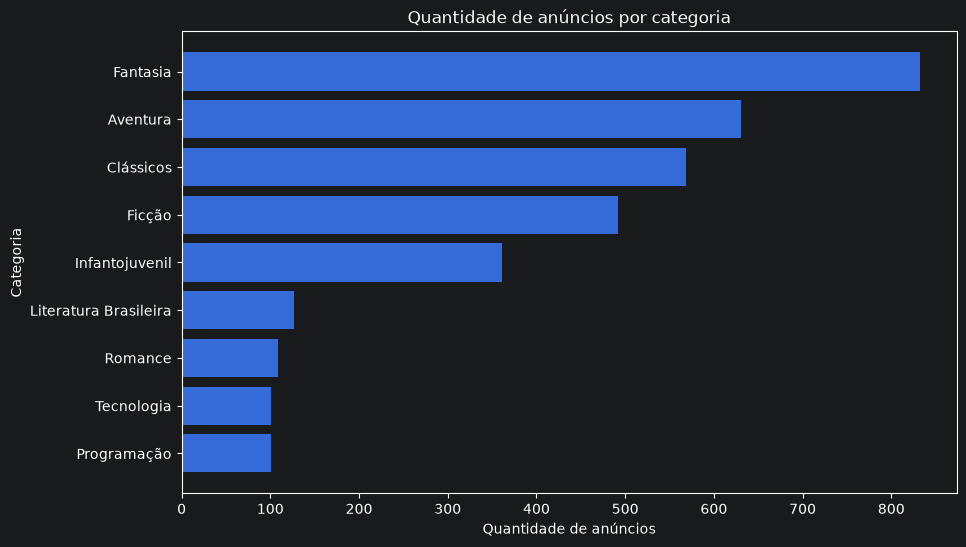

In [31]:
plt.figure(figsize=(10, 6))

plt.barh(
    distribuicao_categorias["categoria"],
    distribuicao_categorias["quantidadeAnuncios"]
)

plt.title("Quantidade de anúncios por categoria")
plt.xlabel("Quantidade de anúncios")
plt.ylabel("Categoria")

plt.gca().invert_yaxis()

plt.show()

### 5.2 Categoria × tipo de negociação

Após identificar as categorias com maior presença entre os anúncios, será analisada sua distribuição entre as modalidades `TROCA`, `VENDA` e `AMBOS`.

Essa análise permite observar como os anúncios de cada categoria estão distribuídos entre as diferentes formas de negociação disponíveis na plataforma.

In [32]:
categoria_tipo = (
    anuncios_por_categoria
    .groupby(["categorias", "tipoNegociacao"])
    .size()
    .reset_index(name="quantidadeAnuncios")
)

categoria_tipo

,categorias,tipoNegociacao,quantidadeAnuncios
0,Aventura,AMBOS,173
1,Aventura,TROCA,247
2,Aventura,VENDA,210
3,Clássicos,AMBOS,136
4,Clássicos,TROCA,225
5,Clássicos,VENDA,208
6,Fantasia,AMBOS,218
7,Fantasia,TROCA,331
8,Fantasia,VENDA,283
9,Ficção,AMBOS,106


In [33]:
tabela_categoria_tipo = (
    categoria_tipo
    .pivot(
        index="categorias",
        columns="tipoNegociacao",
        values="quantidadeAnuncios"
    )
    .fillna(0)
    .astype(int)
)

tabela_categoria_tipo

tipoNegociacao,AMBOS,TROCA,VENDA
categorias,,,
Aventura,173,247,210
Clássicos,136,225,208
Fantasia,218,331,283
Ficção,106,212,174
Infantojuvenil,80,147,134
Literatura Brasileira,31,40,56
Programação,27,40,34
Romance,34,36,39
Tecnologia,27,40,34


Para facilitar a comparação entre categorias com diferentes quantidades de anúncios, será calculada a participação percentual de cada modalidade dentro de cada categoria.

Nesse caso, os percentuais de `TROCA`, `VENDA` e `AMBOS` serão calculados em relação ao total de anúncios associados à própria categoria, fazendo com que a soma das modalidades em cada categoria seja aproximadamente 100%.

In [34]:
percentual_categoria_tipo = (
    tabela_categoria_tipo
    .div(tabela_categoria_tipo.sum(axis=1), axis=0)
    .mul(100)
    .round(2)
)

percentual_categoria_tipo

tipoNegociacao,AMBOS,TROCA,VENDA
categorias,,,
Aventura,27.46,39.21,33.33
Clássicos,23.90,39.54,36.56
Fantasia,26.20,39.78,34.01
Ficção,21.54,43.09,35.37
Infantojuvenil,22.16,40.72,37.12
Literatura Brasileira,24.41,31.50,44.09
Programação,26.73,39.60,33.66
Romance,31.19,33.03,35.78
Tecnologia,26.73,39.60,33.66


A distribuição percentual das modalidades de negociação será apresentada por meio de um gráfico de barras empilhadas. Dessa forma, cada categoria representa 100% dos seus anúncios, permitindo comparar a participação de `TROCA`, `VENDA` e `AMBOS` mesmo entre categorias com diferentes quantidades de publicações.

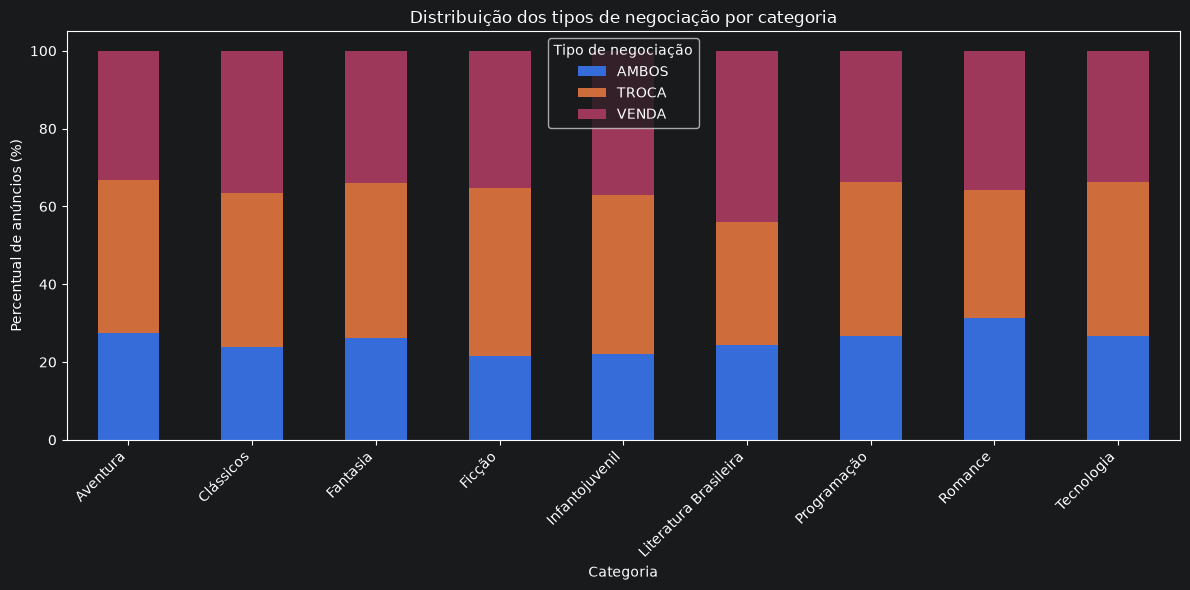

In [35]:
percentual_categoria_tipo.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Distribuição dos tipos de negociação por categoria")
plt.xlabel("Categoria")
plt.ylabel("Percentual de anúncios (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Tipo de negociação")
plt.tight_layout()

plt.show()

As diferenças observadas entre as modalidades demonstram como a metodologia permite comparar a composição dos tipos de negociação entre as categorias. Como os dados utilizados neste experimento são simulados, essas diferenças não devem ser interpretadas como preferências reais dos usuários do Trocabook. A interpretação do comportamento real dependerá da aplicação da mesma análise aos dados armazenados no Firebase Cloud Firestore.

## 6. Análise temporal

Nesta etapa será analisada a evolução da publicação de anúncios ao longo do tempo utilizando o campo `dataCriacao`.

A análise temporal permitirá observar o volume de novos anúncios registrados em cada mês, identificar variações entre períodos e verificar como as diferentes modalidades de negociação evoluem ao longo do histórico analisado.

### 6.1 Novos anúncios por mês

Inicialmente, será calculada a quantidade de novos anúncios cadastrados em cada mês. Essa análise permite observar como o volume de publicações evolui ao longo do período considerado pelo experimento.

In [36]:
anuncios_por_mes = (
    anuncios
    .groupby("mesCriacao")
    .size()
    .reset_index(name="novosAnuncios")
)

anuncios_por_mes

,mesCriacao,novosAnuncios
0,2024-01,25
1,2024-02,28
2,2024-03,26
3,2024-04,31
4,2024-05,29
5,2024-06,33
6,2024-07,30
7,2024-08,35
8,2024-09,32
9,2024-10,38


In [37]:
anuncios_por_mes.tail()

,mesCriacao,novosAnuncios
31,2026-08,65
32,2026-09,62
33,2026-10,68
34,2026-11,64
35,2026-12,70


In [38]:
print(f"Quantidade de meses analisados: {len(anuncios_por_mes)}")
print(f"Menor quantidade mensal: {anuncios_por_mes['novosAnuncios'].min()}")
print(f"Maior quantidade mensal: {anuncios_por_mes['novosAnuncios'].max()}")
print(f"Média mensal: {anuncios_por_mes['novosAnuncios'].mean():.2f}")

Quantidade de meses analisados: 36
Menor quantidade mensal: 25
Maior quantidade mensal: 70
Média mensal: 46.14


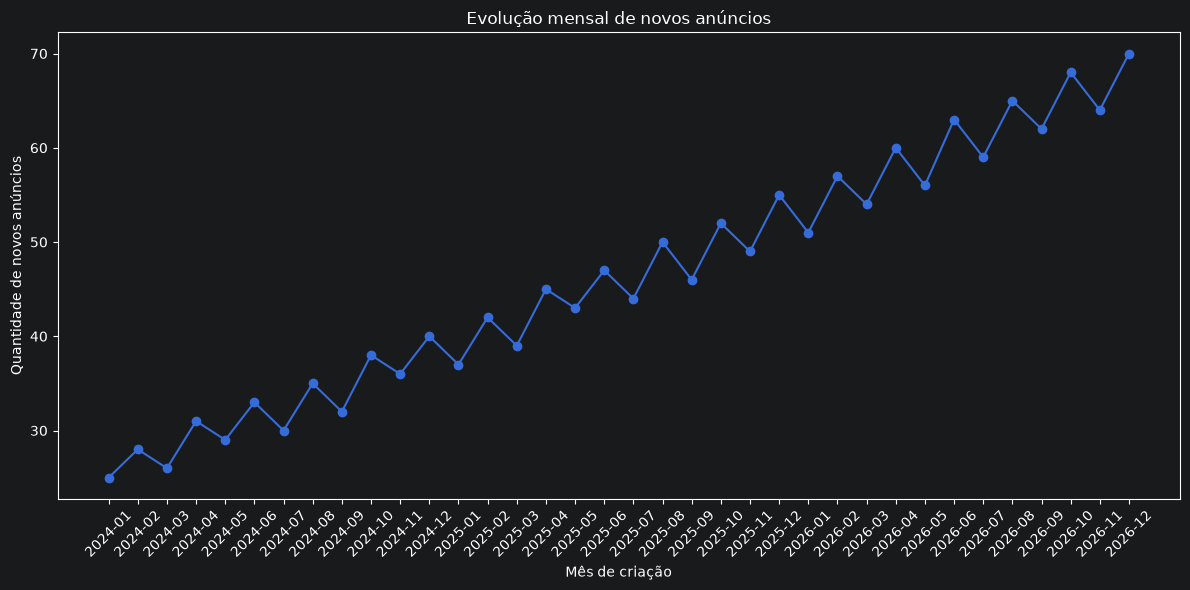

In [39]:
plt.figure(figsize=(12, 6))

plt.plot(
    anuncios_por_mes["mesCriacao"].astype(str),
    anuncios_por_mes["novosAnuncios"],
    marker="o"
)

plt.title("Evolução mensal de novos anúncios")
plt.xlabel("Mês de criação")
plt.ylabel("Quantidade de novos anúncios")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### 6.2 Variação mensal

Além da quantidade absoluta de novos anúncios, será analisada a variação percentual entre meses consecutivos.

Essa análise permite identificar períodos de crescimento ou redução no volume de novos anúncios, complementando a visualização da evolução mensal apresentada anteriormente.

In [40]:
anuncios_por_mes["variacaoPercentual"] = (
    anuncios_por_mes["novosAnuncios"]
    .pct_change()
    .mul(100)
    .round(2)
)

anuncios_por_mes

,mesCriacao,novosAnuncios,variacaoPercentual
0,2024-01,25,NaN
1,2024-02,28,12.00
2,2024-03,26,-7.14
3,2024-04,31,19.23
4,2024-05,29,-6.45
5,2024-06,33,13.79
6,2024-07,30,-9.09
7,2024-08,35,16.67
8,2024-09,32,-8.57
9,2024-10,38,18.75


In [41]:
anuncios_por_mes.tail()

,mesCriacao,novosAnuncios,variacaoPercentual
31,2026-08,65,10.17
32,2026-09,62,-4.62
33,2026-10,68,9.68
34,2026-11,64,-5.88
35,2026-12,70,9.38


In [42]:
maior_crescimento = anuncios_por_mes.loc[
    anuncios_por_mes["variacaoPercentual"].idxmax()
]

maior_reducao = anuncios_por_mes.loc[
    anuncios_por_mes["variacaoPercentual"].idxmin()
]

print(
    f"Maior crescimento mensal: "
    f"{maior_crescimento['mesCriacao']} "
    f"({maior_crescimento['variacaoPercentual']:.2f}%)"
)

print(
    f"Maior redução mensal: "
    f"{maior_reducao['mesCriacao']} "
    f"({maior_reducao['variacaoPercentual']:.2f}%)"
)

Maior crescimento mensal: 2024-04 (19.23%)
Maior redução mensal: 2024-07 (-9.09%)


### 6.3 Evolução por tipo de negociação

Para complementar a análise temporal, será observada a evolução mensal dos anúncios de acordo com sua modalidade de negociação.

Essa análise permite acompanhar como as quantidades de anúncios destinados a `TROCA`, `VENDA` e `AMBOS` variam ao longo do período analisado.

In [43]:
anuncios_mes_tipo = (
    anuncios
    .groupby(["mesCriacao", "tipoNegociacao"])
    .size()
    .reset_index(name="quantidadeAnuncios")
)

anuncios_mes_tipo.head(10)

,mesCriacao,tipoNegociacao,quantidadeAnuncios
0,2024-01,AMBOS,6
1,2024-01,TROCA,7
2,2024-01,VENDA,12
3,2024-02,AMBOS,6
4,2024-02,TROCA,9
5,2024-02,VENDA,13
6,2024-03,AMBOS,8
7,2024-03,TROCA,10
8,2024-03,VENDA,8
9,2024-04,AMBOS,7


In [45]:
evolucao_tipo = (
    anuncios_mes_tipo
    .pivot(
        index="mesCriacao",
        columns="tipoNegociacao",
        values="quantidadeAnuncios"
    )
    .fillna(0)
    .astype(int)
)

evolucao_tipo.head()

tipoNegociacao,AMBOS,TROCA,VENDA
mesCriacao,,,
2024-01,6,7,12
2024-02,6,9,13
2024-03,8,10,8
2024-04,7,13,11
2024-05,11,14,4


In [46]:
evolucao_tipo.tail()

tipoNegociacao,AMBOS,TROCA,VENDA
mesCriacao,,,
2026-08,17,21,27
2026-09,16,26,20
2026-10,16,31,21
2026-11,16,29,19
2026-12,16,22,32


A evolução mensal das modalidades será apresentada graficamente para permitir a comparação entre as quantidades de anúncios destinados a `TROCA`, `VENDA` e `AMBOS` ao longo do período analisado.

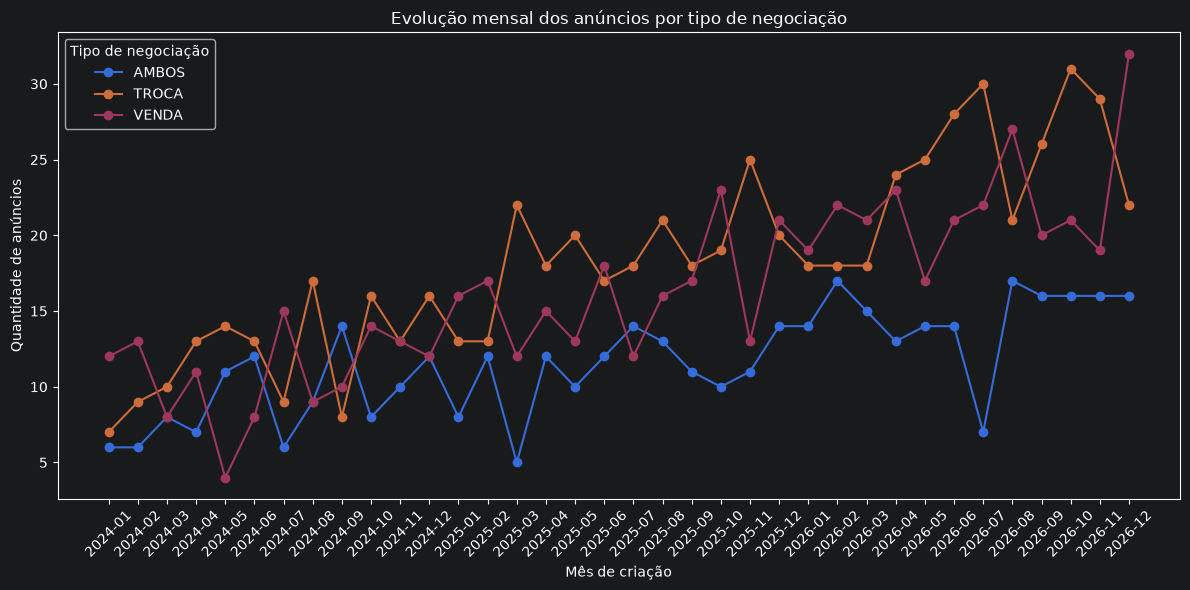

In [47]:
plt.figure(figsize=(12, 6))

for tipo in evolucao_tipo.columns:
    plt.plot(
        evolucao_tipo.index.astype(str),
        evolucao_tipo[tipo],
        marker="o",
        label=tipo
    )

plt.title("Evolução mensal dos anúncios por tipo de negociação")
plt.xlabel("Mês de criação")
plt.ylabel("Quantidade de anúncios")
plt.xticks(rotation=45)
plt.legend(title="Tipo de negociação")
plt.tight_layout()

plt.show()

A visualização permite acompanhar separadamente a evolução das modalidades de negociação ao longo do período analisado. As oscilações observadas decorrem da distribuição dos dados simulados e demonstram como a metodologia pode ser utilizada para identificar mudanças na composição dos anúncios ao longo do tempo.

Como o experimento utiliza dados simulados, essas variações não representam necessariamente mudanças reais no comportamento dos usuários. A interpretação desse comportamento dependerá posteriormente da aplicação da análise aos dados reais do Trocabook.

## 7. Insights automáticos

A partir dos indicadores calculados nas etapas anteriores, podem ser gerados insights automáticos para resumir informações relevantes sobre os anúncios da plataforma.

Esses insights utilizam os resultados das análises já realizadas e os transformam em mensagens de fácil interpretação, que poderão posteriormente ser disponibilizadas pelo serviço de Analytics ao dashboard administrativo do Trocabook.

Como os dados utilizados neste experimento são simulados, as mensagens geradas têm como objetivo validar a metodologia de geração dos insights e não representar conclusões reais sobre o comportamento atual da plataforma.

In [48]:
categoria_destaque = distribuicao_categorias.iloc[0]

tipo_destaque = distribuicao_tipo.iloc[0]

In [49]:
insights = [
    (
        f"A categoria com maior presença nos anúncios é "
        f"{categoria_destaque['categoria']}, presente em "
        f"{categoria_destaque['percentualAnuncios']:.2f}% dos anúncios."
    ),
    (
        f"A modalidade de negociação mais utilizada é "
        f"{tipo_destaque['tipoNegociacao']}, representando "
        f"{tipo_destaque['percentual']:.2f}% dos anúncios."
    ),
    (
        f"O maior crescimento mensal no volume de novos anúncios ocorreu em "
        f"{maior_crescimento['mesCriacao']}, com aumento de "
        f"{maior_crescimento['variacaoPercentual']:.2f}% em relação ao mês anterior."
    ),
    (
        f"A maior redução mensal no volume de novos anúncios ocorreu em "
        f"{maior_reducao['mesCriacao']}, com variação de "
        f"{maior_reducao['variacaoPercentual']:.2f}% em relação ao mês anterior."
    )
]

for insight in insights:
    print(f"- {insight}")

- A categoria com maior presença nos anúncios é Fantasia, presente em 50.09% dos anúncios.
- A modalidade de negociação mais utilizada é TROCA, representando 39.67% dos anúncios.
- O maior crescimento mensal no volume de novos anúncios ocorreu em 2024-04, com aumento de 19.23% em relação ao mês anterior.
- A maior redução mensal no volume de novos anúncios ocorreu em 2024-07, com variação de -9.09% em relação ao mês anterior.


## 8. Conclusão

O experimento permitiu validar uma metodologia para análise dos anúncios cadastrados no Trocabook, abrangendo desde a preparação dos dados até a geração de indicadores e insights que poderão posteriormente ser utilizados pelo serviço de Analytics.

A partir dos dados simulados, foram analisadas a quantidade total de anúncios, a distribuição entre as modalidades de negociação, a presença das diferentes categorias e a relação entre categorias e tipos de negociação. A inclusão do campo `dataCriacao` também possibilitou analisar a evolução mensal das publicações, as variações entre períodos consecutivos e o comportamento das modalidades de negociação ao longo do tempo.

O experimento também demonstrou a importância do tratamento de atributos que podem possuir múltiplos valores, como categorias e autores. A utilização da operação `explode()` permitiu analisar individualmente essas informações sem modificar a estrutura original dos anúncios.

Por fim, os indicadores calculados foram utilizados para gerar insights automáticos de fácil interpretação, demonstrando como os resultados das análises poderão futuramente ser disponibilizados ao dashboard administrativo do Trocabook.

Como o conjunto de dados utilizado neste experimento é simulado, os resultados obtidos não devem ser interpretados como conclusões sobre o comportamento real dos usuários da plataforma. A integração com os dados armazenados no Firebase Cloud Firestore será necessária para que a mesma metodologia seja aplicada aos anúncios reais.

Este experimento possui caráter descritivo e diagnóstico. A previsão da quantidade de novos anúncios em períodos futuros será tratada separadamente em um experimento específico de previsão, utilizando o histórico temporal de criação dos anúncios.